# Artem's solution based on Eli's: TSP on a real quantum computer (IQM Resonance)

A copy of `Eli_solution.ipynb` (depot + 4 delivery points, 16 qubits) that also runs the optimized QAOA circuit on real IQM hardware.

**What stays the same.** Data loading, the classical brute force, the QUBO formulation and its check are Eli's cells, unchanged.

**What is new.**
1. QAOA angles are found by a grid search + zoom (as in Problems 1–3) instead of a fixed start, because with one layer the fixed start gives no valid routes at all.
2. The circuits are translated to the chip's gates and the gate count is shown **before** anything is sent.
3. One hardware job runs all circuits; the measured bitstrings are decoded into routes exactly like Eli's last cell.
4. Simulator vs hardware vs random guessing, side by side.

**Honest expectation.** The circuit needs ~280 two-qubit gates at p = 1 and ~620 at p = 2. With roughly 0.5% error per gate, the chance that a shot runs without any gate error is about 0.995²⁸⁰ ≈ 25% (p = 1) and 0.995⁶²⁰ ≈ 5% (p = 2). Expect results close to random guessing, especially at p = 2. That comparison is itself a result for the "lessons learned" slide.

**Before running.**
- Kernel: *Python (qesthack26-iqm)* (`venv-iqm`: `iqm-client` needs Qiskit 2.1; `qiskit-optimization` is installed there too).
- The IQM token is read from the macOS keychain (service `resonance.iqm.tech`); it is never printed or stored.
- `RUN_ON_HARDWARE = False` by default: everything except the hardware job runs locally.

# ⚙️ Settings: change these before running

- `RUN_ON_HARDWARE`: **set to `True` to send the job to the real quantum computer** (uses the account quota).
- `QUANTUM_COMPUTER`: `"emerald"` (54 qubits), `"garnet"` (20 qubits) or `"sirius"` (16 qubits, star topology with extra MOVE gates).
- `LAYERS_TO_RUN`: QAOA depths to compare; one circuit per entry in the same job.
- `SHOTS`: shots per circuit.

In [13]:
RUN_ON_HARDWARE =   True       # <-- set to True to submit the job to the real quantum computer
QUANTUM_COMPUTER = "emerald"  # "emerald", "garnet" or "sirius"
LAYERS_TO_RUN = [1]           # QAOA depths to compare, e.g. [1, 2] (Eli's notebook uses 2)
SHOTS = 5000                  # per circuit

## Load the data

In [14]:
import json
import numpy as np

with open("tallinn_osrm_matrix.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Number of locations, including depot
n = 5

# Location names
names = [point["name"] for point in data["points"][:n]]

# Distance matrix in kilometres
distances = np.array(data["distances"], dtype=float)[:n, :n] / 1000

print("Locations:")
for i, name in enumerate(names):
    print(f"{i}: {name}")

print("\nDistance matrix (km):")
print(np.round(distances, 2))

Locations:
0: Omniva Pallasti (depot)
1: Kadriorg President's Office
2: Shaurma Kebab Punane
3: Kultuurikatel
4: Patarei Prison

Distance matrix (km):
[[0.   2.68 2.77 3.94 5.14]
 [2.91 0.   4.47 3.22 4.42]
 [2.75 5.21 0.   6.13 7.33]
 [4.22 3.48 6.83 0.   1.39]
 [5.16 4.42 7.77 1.62 0.  ]]


## Optimal route with classical algorithm

In [15]:
from itertools import permutations

def calculate_distance(route, distances):
    return sum(
        distances[route[i], route[i + 1]]
        for i in range(len(route) - 1)
    )

best_distance = float("inf")
best_route = None

# Depot (0) is fixed at the start and end
for order in permutations(range(1, n)):
    route = (0,) + order + (0,)

    total_distance = calculate_distance(route, distances)

    if total_distance < best_distance:
        best_distance = total_distance
        best_route = route

print("Optimal route:")
print(" → ".join(names[i] for i in best_route))

print(f"\nMinimum distance: {best_distance:.2f} km")

Optimal route:
Omniva Pallasti (depot) → Kultuurikatel → Patarei Prison → Kadriorg President's Office → Shaurma Kebab Punane → Omniva Pallasti (depot)

Minimum distance: 16.96 km


## Visualization

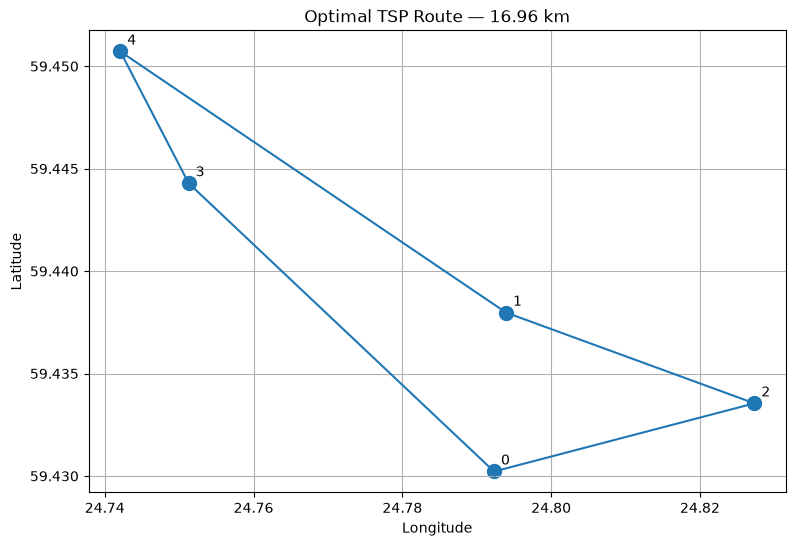

In [16]:
import matplotlib.pyplot as plt

# Coordinates of selected locations
latitudes = [p["lat"] for p in data["points"][:n]]
longitudes = [p["lon"] for p in data["points"][:n]]

plt.figure(figsize=(9, 6))

# Draw locations
plt.scatter(longitudes, latitudes, s=100)

# Draw route
route_lons = [longitudes[i] for i in best_route]
route_lats = [latitudes[i] for i in best_route]

plt.plot(route_lons, route_lats, marker="o")

for i, name in enumerate(names):
    plt.annotate(str(i), (longitudes[i], latitudes[i]),
                 xytext=(5, 5), textcoords="offset points")

plt.title(f"Optimal TSP Route — {best_distance:.2f} km")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

## TSP formulation as QUBO

In [17]:
from qiskit_optimization import QuadraticProgram

n = 5
m = n - 1

qp = QuadraticProgram("Omniva_TSP")

m = n - 1  # Number of delivery locations

# Binary variables: x[i, p] = 1 if location i is visited at position p
for i in range(1, n):
    for p in range(m):
        qp.binary_var(name=f"x_{i}_{p}")

# Objective: minimize total driving distance
linear = {}
quadratic = {}

# Depot -> first delivery
for i in range(1, n):
    linear[f"x_{i}_0"] = distances[0, i]

# Last delivery -> depot
for i in range(1, n):
    name = f"x_{i}_{m-1}"
    linear[name] = linear.get(name, 0) + distances[i, 0]

# Distances between consecutive deliveries
for p in range(m - 1):
    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                quadratic[(f"x_{i}_{p}", f"x_{j}_{p+1}")] = distances[i, j]

qp.minimize(linear=linear, quadratic=quadratic)

# Every location must be visited exactly once
for i in range(1, n):
    qp.linear_constraint(
        linear={f"x_{i}_{p}": 1 for p in range(m)},
        sense="==",
        rhs=1,
        name=f"visit_{i}"
    )

# Every route position must contain exactly one location
for p in range(m):
    qp.linear_constraint(
        linear={f"x_{i}_{p}": 1 for i in range(1, n)},
        sense="==",
        rhs=1,
        name=f"position_{p}"
    )

print(qp.prettyprint())

Problem name: Omniva_TSP

Minimize
  4.471*x_1_0*x_2_1 + 3.221*x_1_0*x_3_1 + 4.42*x_1_0*x_4_1 + 5.207*x_1_1*x_2_0
  + 4.471*x_1_1*x_2_2 + 3.479*x_1_1*x_3_0 + 3.221*x_1_1*x_3_2
  + 4.423*x_1_1*x_4_0 + 4.42*x_1_1*x_4_2 + 5.207*x_1_2*x_2_1 + 4.471*x_1_2*x_2_3
  + 3.479*x_1_2*x_3_1 + 3.221*x_1_2*x_3_3 + 4.423*x_1_2*x_4_1 + 4.42*x_1_2*x_4_3
  + 5.207*x_1_3*x_2_2 + 3.479*x_1_3*x_3_2 + 4.423*x_1_3*x_4_2
  + 6.134*x_2_0*x_3_1 + 7.334*x_2_0*x_4_1 + 6.826*x_2_1*x_3_0
  + 6.134*x_2_1*x_3_2 + 7.77*x_2_1*x_4_0 + 7.334*x_2_1*x_4_2 + 6.826*x_2_2*x_3_1
  + 6.134*x_2_2*x_3_3 + 7.77*x_2_2*x_4_1 + 7.334*x_2_2*x_4_3 + 6.826*x_2_3*x_3_2
  + 7.77*x_2_3*x_4_2 + 1.387*x_3_0*x_4_1 + 1.625*x_3_1*x_4_0 + 1.387*x_3_1*x_4_2
  + 1.625*x_3_2*x_4_1 + 1.387*x_3_2*x_4_3 + 1.625*x_3_3*x_4_2 + 2.676*x_1_0
  + 2.909*x_1_3 + 2.768*x_2_0 + 2.747*x_2_3 + 3.937*x_3_0 + 4.219*x_3_3
  + 5.136*x_4_0 + 5.163*x_4_3

Subject to
  Linear constraints (8)
    x_1_0 + x_1_1 + x_1_2 + x_1_3 == 1  'visit_1'
    x_2_0 + x_2_1 + x_2_2 + x_

## QUBO -> Ising Hamiltonian

In [18]:
from qiskit_optimization.converters import QuadraticProgramToQubo

# Convert constrained optimization problem to QUBO
penalty = 100

converter = QuadraticProgramToQubo(penalty=penalty)
qubo = converter.convert(qp)

# Convert QUBO to Ising Hamiltonian
H_raw, offset = qubo.to_ising()

# Scale Hamiltonian
H = (H_raw / penalty).simplify()

print("QUBO variables:", qubo.get_num_binary_vars())
print("Qubits:", H.num_qubits)
print("Hamiltonian terms:", len(H))

QUBO variables: 16
Qubits: 16
Hamiltonian terms: 100


## Check QUBO

In [19]:
import numpy as np

# Optimal route without depot
delivery_order = best_route[1:-1]

# Encode route as binary variables
assignment = {
    f"x_{i}_{p}": int(delivery_order[p] == i)
    for i in range(1, n)
    for p in range(m)
}

x = np.array([
    assignment[var.name]
    for var in qp.variables
])

print("Optimal route:", best_route)
print("Classical distance:", best_distance)
print("QP objective:", qp.objective.evaluate(x))
print("QUBO objective:", qubo.objective.evaluate(x))
print("Constraints satisfied:", qp.is_feasible(x))

Optimal route: (0, 3, 4, 1, 2, 0)
Classical distance: 16.965
QP objective: 16.965
QUBO objective: 16.965000000000146
Constraints satisfied: True


## QAOA angles: grid search instead of a fixed start

**Why not Eli's start.** Eli starts COBYLA from all angles = 0.5. That works for p = 2, but with one layer it gets stuck: on the ideal simulator the p = 1 circuit returned **0 valid routes in 5,000 shots**, worse than random guessing. So for p = 1 we search the angles the way we did in Problems 1–3.

**What we maximize.** The probability of measuring a *valid* route. The penalty (100) is much larger than the distances (a few km), so after scaling all 24 valid routes have almost the same energy (−16.40 … −16.31) and QAOA can barely tell them apart. What it *can* do is concentrate the shots on valid routes; the shortest valid route is then picked classically from the samples.

**How.**
1. **A fast simulator.** The Hamiltonian contains only Z terms, so each of the 65,536 bitstrings simply has an energy. One QAOA layer = multiply every amplitude by $e^{-i\gamma E}$, then mix each amplitude with its partner differing in one qubit ($\cos\beta$, $-i\sin\beta$). About 2 ms per circuit instead of ~100 ms with Qiskit. Checked against Qiskit's `Statevector` (overlap 1.0).
2. **Map of one layer.** P(valid) on a 48 × 240 grid of $(\beta, \gamma)$. There is no neat period here (the coefficients are not integers, and there is no bit-flip symmetry), so the grid covers $\beta \in [0, \pi)$ and $\gamma \in [0, 2\pi)$.
3. **Zoom** around the 6 best local maxima: an 11 × 11 grid around each, best point kept, step shrunk 5× each time, 4 times.
4. **More layers** (if `LAYERS_TO_RUN` contains p > 1): the p − 1 schedule is stretched to p layers (INTERP) and COBYLA fine-tunes all angles, maximizing P(valid).

fast simulator vs Qiskit: overlap 1.000000000000
p = 1: beta = 0.4527, gamma = 5.8060, P(valid) = 5.66 %  (30 s)


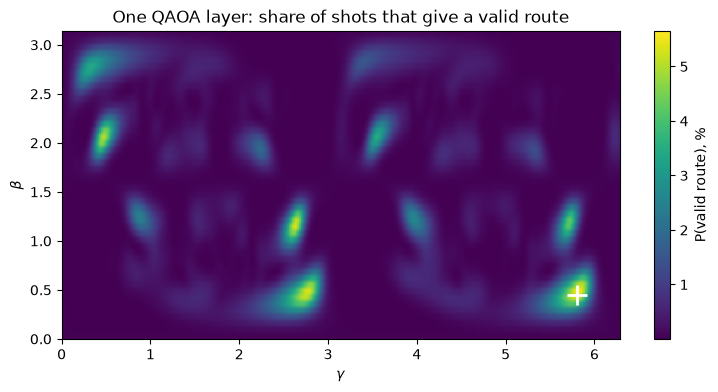

Qiskit circuits reproduce the optimized probabilities


In [20]:
import time

from qiskit import transpile
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

N_QUBITS = H.num_qubits
ENERGIES = np.real(H.to_matrix(sparse=True).diagonal())


def valid_index(order):
    # statevector index of the bitstring that encodes this delivery order
    bits = {f"x_{i}_{p}": int(order[p] == i) for i in range(1, n) for p in range(m)}
    return sum(bits[var.name] << k for k, var in enumerate(qp.variables))


VALID_INDICES = np.array([valid_index(order) for order in permutations(range(1, n))])


def simulate(params):
    # QAOA state for params = [beta_0..beta_{p-1}, gamma_0..gamma_{p-1}] (same order as QAOAAnsatz)
    p = len(params) // 2
    state = np.full(2**N_QUBITS, 2 ** (-N_QUBITS / 2), dtype=complex)
    for beta, gamma in zip(params[:p], params[p:]):
        state = (state * np.exp(-1j * gamma * ENERGIES)).reshape((2,) * N_QUBITS)
        for axis in range(N_QUBITS):
            state = np.cos(beta) * state - 1j * np.sin(beta) * np.flip(state, axis=axis)
        state = state.reshape(-1)
    return state


def p_valid(params):
    return np.sum(np.abs(simulate(np.asarray(params))[VALID_INDICES]) ** 2)


check = np.array([0.3, 0.7])
reference = Statevector(QAOAAnsatz(H, reps=1).decompose(reps=2).assign_parameters(check)).data
print(f"fast simulator vs Qiskit: overlap {abs(np.vdot(reference, simulate(check))):.12f}")

# map of one layer + zoom
start = time.time()
betas = np.linspace(0, np.pi, 48, endpoint=False)
gammas = np.linspace(0, 2 * np.pi, 240, endpoint=False)
grid = np.array([[p_valid([b, g]) for g in gammas] for b in betas])
is_peak = grid == maximum_filter(grid, size=3, mode="wrap")
rows, cols = np.nonzero(is_peak)
best_point, best_value = None, -1.0
for k in np.argsort(grid[rows, cols])[::-1][:6]:
    point = np.array([betas[rows[k]], gammas[cols[k]]])
    step = np.array([betas[1] - betas[0], gammas[1] - gammas[0]])
    for _ in range(4):
        sub_b = np.linspace(point[0] - step[0], point[0] + step[0], 11)
        sub_g = np.linspace(point[1] - step[1], point[1] + step[1], 11)
        sub = np.array([[p_valid([b, g]) for g in sub_g] for b in sub_b])
        i, j = np.unravel_index(np.argmax(sub), sub.shape)
        point, step = np.array([sub_b[i], sub_g[j]]), step / 5
    if p_valid(point) > best_value:
        best_point, best_value = point, p_valid(point)
print(f"p = 1: beta = {best_point[0]:.4f}, gamma = {best_point[1]:.4f}, P(valid) = {100 * best_value:.2f} %  ({time.time() - start:.0f} s)")

plt.figure(figsize=(9, 4))
plt.imshow(100 * grid, origin="lower", aspect="auto", cmap="viridis", extent=[0, 2 * np.pi, 0, np.pi])
plt.colorbar(label="P(valid route), %")
plt.plot(best_point[1], best_point[0], "w+", markersize=14, markeredgewidth=2)
plt.xlabel(r"$\gamma$")
plt.ylabel(r"$\beta$")
plt.title("One QAOA layer: share of shots that give a valid route")
plt.show()


def interp_schedule(params):
    p = len(params) // 2

    def stretch(schedule):
        padded = np.concatenate([[0.0], schedule, [0.0]])
        return np.array([(i - 1) / p * padded[i - 1] + (p - i + 1) / p * padded[i] for i in range(1, p + 2)])

    return np.concatenate([stretch(params[:p]), stretch(params[p:])])


schedules = {1: best_point}
for reps in range(2, max(LAYERS_TO_RUN) + 1):
    res = minimize(lambda x: -p_valid(x), interp_schedule(schedules[reps - 1]),
                   method="COBYLA", options={"maxiter": 2000, "rhobeg": 0.05})
    schedules[reps] = res.x
    print(f"p = {reps}: P(valid) = {100 * p_valid(res.x):.2f} %")

# circuits for the next cells (same parameter order as QAOAAnsatz)
ansatz_by_p, params_by_p = {}, {}
for reps in LAYERS_TO_RUN:
    ansatz_by_p[reps] = transpile(QAOAAnsatz(cost_operator=H, reps=reps), basis_gates=["h", "rx", "rz", "cx"],
                                  optimization_level=1)
    params_by_p[reps] = schedules[reps]
    exact = Statevector.from_instruction(ansatz_by_p[reps].assign_parameters(params_by_p[reps])).probabilities()
    assert abs(exact[VALID_INDICES].sum() - p_valid(params_by_p[reps])) < 1e-9, "Qiskit circuit disagrees with the fast simulator"
print("Qiskit circuits reproduce the optimized probabilities")

## Decoding measurements into routes

One function for both the simulator and the hardware, built from Eli's last cell: a measured bitstring is a valid route only if every delivery point appears exactly once and every position holds exactly one point (`qp.is_feasible`). For valid routes we compute the distance.

**Reference: random guessing.** 16 qubits give 2¹⁶ = 65,536 bitstrings, of which only 4! = 24 are valid routes (0.037%) and 1 is the optimum (0.0015%).

In [21]:
from itertools import permutations


def decode(bitstring):
    # Qiskit bitstring (qubit 0 rightmost) -> route tuple, or None if invalid
    bits = np.array([int(b) for b in bitstring[::-1]])
    if not qp.is_feasible(bits):
        return None
    order = []
    for p in range(m):
        for i in range(1, n):
            if bits[qp.variables_index[f"x_{i}_{p}"]] == 1:
                order.append(i)
                break
    return (0,) + tuple(order) + (0,)


def evaluate(counts):
    # share of valid routes, share of the optimal route, best sampled route
    shots = sum(counts.values())
    valid, optimal, best = 0, 0, (None, float("inf"))
    for bitstring, count in counts.items():
        route = decode(bitstring)
        if route is None:
            continue
        valid += count
        distance = calculate_distance(route, distances)
        if np.isclose(distance, best_distance):
            optimal += count
        if distance < best[1]:
            best = (route, distance)
    return {"valid %": 100 * valid / shots, "optimal %": 100 * optimal / shots,
            "best route": best[0], "best km": best[1]}


RANDOM = {"valid %": 100 * 24 / 2**16, "optimal %": 100 / 2**16}
ideal = {}
for reps in LAYERS_TO_RUN:
    state = Statevector.from_instruction(ansatz_by_p[reps].assign_parameters(params_by_p[reps]))
    state.seed(42)
    ideal[reps] = evaluate(state.sample_counts(shots=SHOTS))
    print(f"simulator, p = {reps}: {ideal[reps]}")
print(f"random guessing: valid {RANDOM['valid %']:.3f} %, optimal {RANDOM['optimal %']:.4f} %")

simulator, p = 1: {'valid %': np.float64(5.86), 'optimal %': np.float64(0.1), 'best route': (0, 3, 4, 1, 2, 0), 'best km': np.float64(16.965)}
random guessing: valid 0.037 %, optimal 0.0015 %


## Translating the circuits for the chip

The chip only has single-qubit rotations (`r`) and the two-qubit gate `cz`, and each qubit talks only to its neighbours, so the transpiler inserts SWAPs. The number of CZ gates is the main source of noise; the last column is a rough chance that a shot passes through all CZ gates without an error, assuming 0.5% error per gate.

In [22]:
import os
import subprocess

from iqm.qiskit_iqm import IQMProvider

if "IQM_TOKEN" not in os.environ:  # read the keychain once per kernel session; IQMProvider picks IQM_TOKEN up itself
    os.environ["IQM_TOKEN"] = subprocess.run(["security", "find-generic-password", "-s", "resonance.iqm.tech", "-w"],
                                             capture_output=True, text=True, check=True).stdout.strip()
backend = IQMProvider("https://resonance.iqm.tech/", quantum_computer=QUANTUM_COMPUTER).get_backend()
print(f"Backend: {QUANTUM_COMPUTER}, {backend.num_qubits} qubits")

transpiled = {}
for reps in LAYERS_TO_RUN:
    circuit = ansatz_by_p[reps].assign_parameters(params_by_p[reps])
    circuit.measure_all()
    transpiled[reps] = transpile(circuit, backend, optimization_level=3, seed_transpiler=1)

print(" p | CZ on chip | MOVE | depth | rough error-free chance")
for reps, circuit in transpiled.items():
    ops = circuit.count_ops()
    print(f"{reps:2d} | {ops.get('cz', 0):10d} | {ops.get('move', 0):4d} | {circuit.depth():5d} | {100 * 0.995 ** ops.get('cz', 0):5.1f} %")

Backend: emerald, 54 qubits
 p | CZ on chip | MOVE | depth | rough error-free chance
 1 |        280 |    0 |   275 |  24.6 %


## Running on the quantum computer

All circuits go into one job. Nothing happens while `RUN_ON_HARDWARE` is `False`. With `True` the job id is printed immediately, then the cell waits for the result (depends on the queue).

In [24]:
if RUN_ON_HARDWARE:
    if "job" not in globals():  # submit only once per kernel session: re-running this cell reuses the job
        job = backend.run([transpiled[reps] for reps in LAYERS_TO_RUN], shots=SHOTS)
    print("Job:", job.job_id())
    counts_list = job.result().get_counts()
    if isinstance(counts_list, dict):  # with one circuit Qiskit returns a single dict, not a list
        counts_list = [counts_list]
    hardware_counts = dict(zip(LAYERS_TO_RUN, counts_list))
    hardware = {reps: evaluate(c) for reps, c in hardware_counts.items()}
    for reps, res in hardware.items():
        print(f"{QUANTUM_COMPUTER}, p = {reps}: {res}")
else:
    print("RUN_ON_HARDWARE is False: nothing submitted.")


Job: 01a1d093-3a7d-76f8-8451-91de8ef0bc65
emerald, p = 1: {'valid %': 0.1, 'optimal %': 0.0, 'best route': (0, 1, 2, 3, 4, 0), 'best km': np.float64(19.831000000000003)}


## Simulator vs hardware vs random guessing

"Valid %" is the share of shots that decode into a real route; "optimal %" is the share that hit the classical optimum. "Best km" is the shortest route found among all shots: even a noisy device can still *sample* the optimum once, which is enough if we check every sample classically.

                        valid %  optimal %  best km  best route
random guessing           0.037     0.0015
simulator, p = 1          5.860     0.1000   16.965  (0, 3, 4, 1, 2, 0)
emerald, p = 1            0.100     0.0000   19.831  (0, 1, 2, 3, 4, 0)

Classical optimum: 16.965 km, route (0, 3, 4, 1, 2, 0)


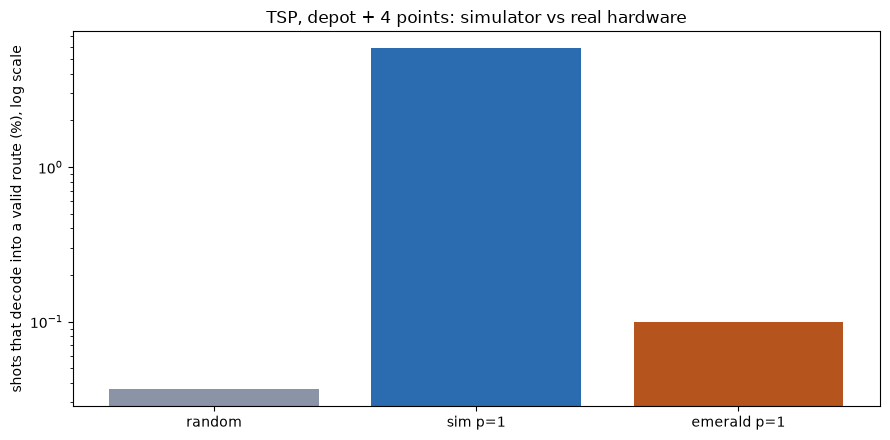

In [25]:
if RUN_ON_HARDWARE:
    print(f"{'':22s} {'valid %':>8s} {'optimal %':>10s} {'best km':>8s}  best route")
    print(f"{'random guessing':22s} {RANDOM['valid %']:8.3f} {RANDOM['optimal %']:10.4f}")
    for reps in LAYERS_TO_RUN:
        for label, res in [(f"simulator, p = {reps}", ideal[reps]), (f"{QUANTUM_COMPUTER}, p = {reps}", hardware[reps])]:
            best_km = f"{res['best km']:8.3f}" if res["best route"] else "       –"
            print(f"{label:22s} {res['valid %']:8.3f} {res['optimal %']:10.4f} {best_km}  {res['best route']}")
    print(f"\nClassical optimum: {best_distance:.3f} km, route {best_route}")

    fig, ax = plt.subplots(figsize=(9, 4.5))
    labels = ["random"] + [f"sim p={r}" for r in LAYERS_TO_RUN] + [f"{QUANTUM_COMPUTER} p={r}" for r in LAYERS_TO_RUN]
    values = [RANDOM["valid %"]] + [ideal[r]["valid %"] for r in LAYERS_TO_RUN] + [hardware[r]["valid %"] for r in LAYERS_TO_RUN]
    ax.bar(labels, values, color=["#8A94A6"] + ["#2B6CB0"] * len(LAYERS_TO_RUN) + ["#B5541C"] * len(LAYERS_TO_RUN))
    ax.set_yscale("log")
    ax.set_ylabel("shots that decode into a valid route (%), log scale")
    ax.set_title("TSP, depot + 4 points: simulator vs real hardware")
    plt.tight_layout()
    plt.show()